# Collect Data

In [1]:
%pip install pandas numpy seaborn matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np

In [3]:
import time
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import Ridge, Lasso, LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

In [4]:
df = pd.read_csv('final_data.csv')
df

,Idade,Petroleo,Agua,Gas,Gas_Royalties,Tempo_Producao,Grau_API,Densidade_GLP_Gas,PCS,Nome_Poco_ANP
0,4073,10597.4769,4800.2166,56.5923,1355.916,744,33.30,2.02232,40592.3314,3-BRSA-1024-SPS
1,3702,3245.1189,8032.5534,16.1271,386.394,744,33.30,2.02232,40592.3314,7-PRA-2-SPS
2,3563,0.0000,0.0000,0.0000,0.000,0,33.30,2.02232,40592.3314,7-BAN-2-SPS
3,4128,2116.3271,5439.4737,25.6074,613.536,714,33.30,2.02232,40592.3314,9-BRSA-999-SPS
4,3609,1978.3072,5187.5167,16.1911,387.928,712,33.30,2.02232,40592.3314,7-BAN-1-SPS
...,...,...,...,...,...,...,...,...,...,...
24521,14311,221.0590,4176.8396,0.8269,25.633,580,22.86,2.01722,40657.3157,7-PG-19D-RJS
24522,14562,253.8190,1296.9182,1.2978,40.232,661,22.86,2.01722,40657.3157,7-PG-12D-RJS
24523,14893,635.0981,1784.2771,1.9080,59.149,727,22.86,2.01722,40657.3157,7-PG-4-RJS
24524,14154,460.4175,4570.8658,1.3961,43.278,725,22.86,2.01722,40657.3157,7-PG-24D-RJS


In [5]:
from math import log

In [6]:
df['Agua_log'] = df['Agua'].apply(lambda x: log(x) if x > 0 else 0)
df['Gas_log'] = df['Gas'].apply(lambda x: log(x) if x > 0 else 0)
df['Idade2'] = df['Idade'].apply(lambda x: x**2)
df

,Idade,Petroleo,Agua,Gas,Gas_Royalties,Tempo_Producao,Grau_API,Densidade_GLP_Gas,PCS,Nome_Poco_ANP,Agua_log,Gas_log,Idade2
0,4073,10597.4769,4800.2166,56.5923,1355.916,744,33.30,2.02232,40592.3314,3-BRSA-1024-SPS,8.476416,4.035873,16589329
1,3702,3245.1189,8032.5534,16.1271,386.394,744,33.30,2.02232,40592.3314,7-PRA-2-SPS,8.991258,2.780501,13704804
2,3563,0.0000,0.0000,0.0000,0.000,0,33.30,2.02232,40592.3314,7-BAN-2-SPS,0.000000,0.000000,12694969
3,4128,2116.3271,5439.4737,25.6074,613.536,714,33.30,2.02232,40592.3314,9-BRSA-999-SPS,8.601438,3.242881,17040384
4,3609,1978.3072,5187.5167,16.1911,387.928,712,33.30,2.02232,40592.3314,7-BAN-1-SPS,8.554010,2.784462,13024881
...,...,...,...,...,...,...,...,...,...,...,...,...,...
24521,14311,221.0590,4176.8396,0.8269,25.633,580,22.86,2.01722,40657.3157,7-PG-19D-RJS,8.337310,-0.190072,204804721
24522,14562,253.8190,1296.9182,1.2978,40.232,661,22.86,2.01722,40657.3157,7-PG-12D-RJS,7.167746,0.260671,212051844
24523,14893,635.0981,1784.2771,1.9080,59.149,727,22.86,2.01722,40657.3157,7-PG-4-RJS,7.486769,0.646056,221801449
24524,14154,460.4175,4570.8658,1.3961,43.278,725,22.86,2.01722,40657.3157,7-PG-24D-RJS,8.427458,0.333683,200335716


In [7]:
target_column = 'Petroleo'
ignore_columns = [
    'Nome_Poco_ANP', 'PCS'
]

In [8]:
sample_df = df.sample(frac=1, random_state=42)
sample_df.drop_duplicates(inplace=True)
columns = [col for col in sample_df.columns if col not in ignore_columns]
for col in columns:
    Q1 = sample_df[col].quantile(0.25)
    Q3 = sample_df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    sample_df = sample_df[(sample_df[col] >= lower_bound) & (sample_df[col] <= upper_bound)]

sample_df

,Idade,Petroleo,Agua,Gas,Gas_Royalties,Tempo_Producao,Grau_API,Densidade_GLP_Gas,PCS,Nome_Poco_ANP,Agua_log,Gas_log,Idade2
20903,6504,69.0258,1838.2138,3.9229,121.601,741,30.23,2.15079,35009.5128,7-SER-21DA-RNS,7.516550,1.366831,42302016
11075,622,5072.2519,60.0237,10.7341,321.711,637,13.42,2.10547,37502.5301,7-PRG-80HP-RJS,4.094739,2.373426,386884
4252,6468,1183.8165,1994.3474,8.9453,277.056,733,24.00,2.04402,40091.4179,7-JUB-6HB-ESS,7.598072,2.191128,41835024
7615,5189,258.2740,977.8236,1.7193,52.995,726,18.10,2.12516,36539.5523,7-ARGO-2H-ESS,6.885329,0.541917,26925721
5359,5591,218.1283,1941.8352,0.4434,13.303,714,30.23,2.12184,36715.5245,7-SER-20D-RNS,7.571389,-0.813283,31259281
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6265,5463,0.0000,0.0000,0.0000,0.000,0,18.10,2.00677,39989.7428,7-ABA-2D-ESS,0.000000,0.000000,29844369
11964,488,102.3119,5.0487,3.9909,56.696,62,30.20,2.00144,38798.0539,7-TUP-128D-RJS,1.619131,1.384017,238144
5390,348,578.2746,0.5789,9.2298,264.040,61,24.70,2.01939,40444.9634,7-MLL-90H-RJS,-0.546626,2.222437,121104
860,2638,132.0420,3.2312,5.2944,76.693,619,30.20,2.00144,38798.0539,7-LL-80DB-RJS,1.172854,1.666650,6959044


In [9]:
pocos_teste = list(sample_df['Nome_Poco_ANP'].value_counts().head(30).keys())

In [10]:
train = sample_df[~sample_df['Nome_Poco_ANP'].isin(pocos_teste)]
test = sample_df[sample_df['Nome_Poco_ANP'].isin(pocos_teste)]

X_train = train.drop([target_column] + ignore_columns, axis=1)
y_train = train[target_column]

X_test = test.drop([target_column] + ignore_columns, axis=1)
y_test = test[target_column]

In [11]:
# X = sample_df.drop(ignore_columns + [target_column], axis=1)
# y = sample_df[target_column]
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.18, random_state=42)

In [12]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

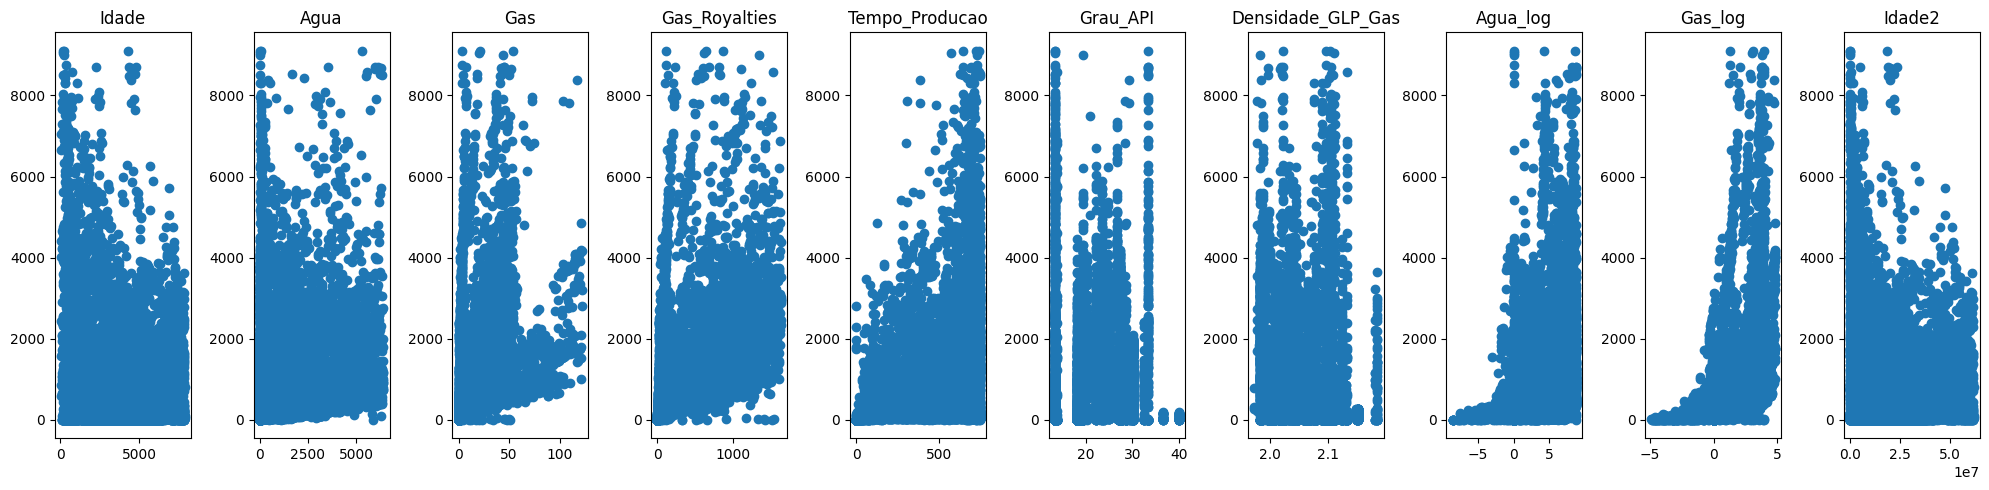

In [13]:
import matplotlib.pyplot as plt

num_features = X_train.columns.size
fig, axes = plt.subplots(nrows=1, ncols=num_features, figsize=(20, 5))

for i, col in enumerate(X_train.columns):
    axes[i].scatter(X_train[col], y_train)
    axes[i].set_title(col)
    
plt.tight_layout()
plt.show()

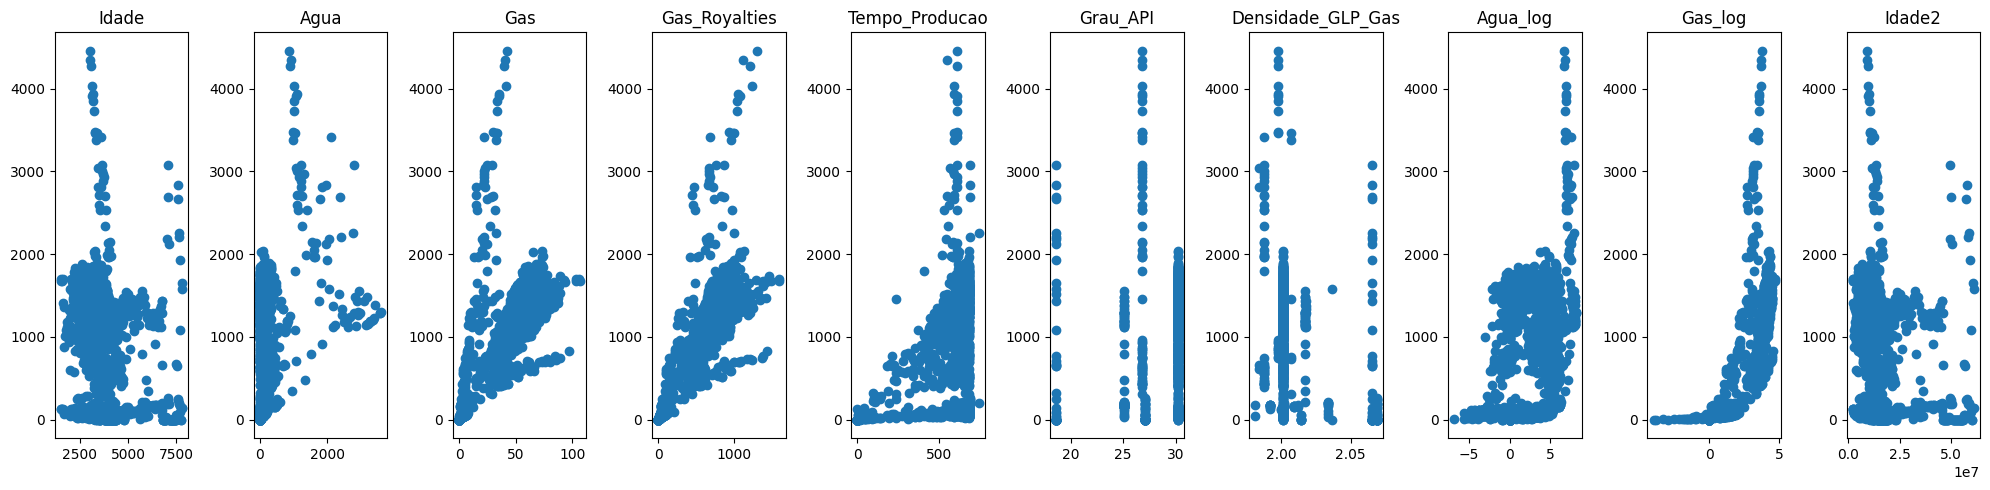

In [14]:
num_features = X_test.columns.size
fig, axes = plt.subplots(nrows=1, ncols=num_features, figsize=(20, 5))

for i, col in enumerate(X_test.columns):
    axes[i].scatter(X_test[col], y_test)
    axes[i].set_title(col)
    
plt.tight_layout()
plt.show()

# Evaluate Methods

In [15]:
results_df = pd.DataFrame()

def evaluate_and_record(model_name, model, X_train, y_train, X_test, y_test, best_params=None):
    global results_df
    
    start_time = time.time()
    model.fit(X_train, y_train)
    end_time = time.time()
    training_time = end_time - start_time
    
    y_pred_treino = model.predict(X_train)
    y_pred_teste = model.predict(X_test)
    
    rmse_treino = np.sqrt(mean_squared_error(y_train, y_pred_treino))
    r2_treino = r2_score(y_train, y_pred_treino)
    mae_treino = mean_absolute_error(y_train, y_pred_treino)
    
    rmse_teste = np.sqrt(mean_squared_error(y_test, y_pred_teste))
    r2_teste = r2_score(y_test, y_pred_teste)
    mae_teste = mean_absolute_error(y_test, y_pred_teste)
    
    new_row = {
        'Modelo': model_name,
        'R2 Treino': r2_treino,
        'R2 Teste': r2_teste,
        'RMSE Treino': rmse_treino,
        'RMSE Teste': rmse_teste,
        'MAE Treino': mae_treino,
        'MAE Teste': mae_teste,
        'Tempo (segundos)': training_time,
        'Hyperparametros': str(best_params) if best_params else 'N/A'
    }
    
    results_df = pd.concat([results_df, pd.DataFrame([new_row])], ignore_index=True)
    return model

In [16]:
def record_gridsearch_details(grid_search_object, model_prefix):
    global results_df
    
    results = pd.DataFrame(grid_search_object.cv_results_)
    
    for index, row in results.iterrows():
        mean_r2_cv = row['mean_test_score']
        
        mean_fit_time = row['mean_fit_time']
        
        model_name_detail = f"{model_prefix} - Combinacao {index + 1}"
        
        new_row = {
            'Modelo': model_name_detail,
            'R2 Teste': mean_r2_cv,
            'RMSE Teste': np.nan,
            'Tempo (s)': mean_fit_time,
            'Detalhes': f"Combin. Testada (Rank: {row['rank_test_score']})",
            'Hyperparametros': str(row['params'])
        }
        
        results_df = pd.concat([results_df, pd.DataFrame([new_row])], ignore_index=True)

# LinearRegression

In [17]:
model = LinearRegression()
evaluate_and_record("Regressao Linear", model, X_train_scaled, y_train, X_test_scaled, y_test)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


# Ridge

In [18]:
alphas = np.logspace(-4, 2, 150)

scoring_metric = 'r2'
ridge_model = Ridge(random_state=42)
grid_search_ridge = GridSearchCV(
    estimator=ridge_model,
    param_grid={'alpha': alphas},
    scoring=scoring_metric,
    cv=5,
    verbose=1,
    n_jobs=-1
)

grid_search_ridge.fit(X_train_scaled, y_train)

best_alpha_ridge = grid_search_ridge.best_params_['alpha']
best_ridge_model = grid_search_ridge.best_estimator_

Fitting 5 folds for each of 150 candidates, totalling 750 fits


In [19]:
evaluate_and_record('Ridge Otimo', best_ridge_model, X_train_scaled, y_train, X_test_scaled, y_test, best_alpha_ridge)

,alpha,np.float64(2.035751822261104)
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,42


# Lasso

In [20]:
lasso_model = Lasso(random_state=42, max_iter=2000) 
grid_search_lasso = GridSearchCV(
    estimator=lasso_model,
    param_grid={'alpha': alphas},
    scoring=scoring_metric,
    cv=5,
    verbose=1,
    n_jobs=-1
)

grid_search_lasso.fit(X_train_scaled, y_train)

best_alpha_lasso = grid_search_lasso.best_params_['alpha']
best_lasso_model = grid_search_lasso.best_estimator_

Fitting 5 folds for each of 150 candidates, totalling 750 fits


In [21]:
evaluate_and_record('Lasso Otimo', best_lasso_model, X_train_scaled, y_train, X_test_scaled, y_test, best_alpha_lasso)

,alpha,np.float64(0....7852651001318)
,fit_intercept,True
,precompute,False
,copy_X,True
,max_iter,2000
,tol,0.0001
,warm_start,False
,positive,False
,random_state,42
,selection,'cyclic'


# Random Forest

In [22]:
from sklearn.ensemble import RandomForestRegressor

In [23]:
rf_model = RandomForestRegressor(random_state=42)
grid_search_rf = GridSearchCV(
    estimator=rf_model,
    param_grid={
        'n_estimators': [400, 800, 1000],
        'max_depth': [None],
        'min_samples_split': range(1, 6, 2),
        'min_samples_leaf': range(1, 6, 2),
        'bootstrap': [True, False]
    },
    scoring=scoring_metric,
    cv=5,
    verbose=1,
    n_jobs=-1
)

grid_search_rf.fit(X_train_scaled, y_train)

best_n_estimators_rf = grid_search_rf.best_params_['n_estimators']
best_max_depth_rf = grid_search_rf.best_params_['max_depth']
best_min_samples_split_rf = grid_search_rf.best_params_['min_samples_split']
best_min_samples_leaf_rf = grid_search_rf.best_params_['min_samples_leaf']
best_bootstrap_rf = grid_search_rf.best_params_['bootstrap']
best_rf_model = grid_search_rf.best_estimator_

Fitting 5 folds for each of 54 candidates, totalling 270 fits


c:\Users\PC GAMER\Downloads\Codigos_mestrado\venv\Lib\site-packages\sklearn\model_selection\_validation.py:516: FitFailedWarning: 
90 fits failed out of a total of 270.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
90 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\PC GAMER\Downloads\Codigos_mestrado\venv\Lib\site-packages\sklearn\model_selection\_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\PC GAMER\Downloads\Codigos_mestrado\venv\Lib\site-packages\sklearn\base.py", line 1358, in wrapper
    estimator._validate_params()
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "c:\Users\PC GAMER\D

In [24]:
evaluate_and_record('Random Forest Otimo', best_rf_model, X_train_scaled, y_train, X_test_scaled, y_test, grid_search_rf.best_params_)

,n_estimators,1000
,criterion,'squared_error'
,max_depth,None
,min_samples_split,3
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


# Gradient Boosting

In [25]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [26]:
from xgboost import XGBRegressor

In [27]:
xgb_model = XGBRegressor(objective='reg:squarederror', random_state=42)
grid_search_xgb = GridSearchCV(
    estimator=xgb_model,
    param_grid={
        'n_estimators': [500, 700, 1000, 1200],
        'learning_rate': [0.01, 0.1, 0.3],
        'max_depth': [3, 5, 7],
        'subsample': [0.7, 1.0],
    },
    scoring=scoring_metric,
    cv=5,
    verbose=1,
    n_jobs=-1
)
grid_search_xgb.fit(X_train_scaled, y_train)

best_n_estimators_xgb = grid_search_xgb.best_params_['n_estimators']
best_max_depth_xgb = grid_search_xgb.best_params_['max_depth']
best_learning_rate_xgb = grid_search_xgb.best_params_['learning_rate']
best_subsample_xgb = grid_search_xgb.best_params_['subsample']
best_xgb_model = grid_search_xgb.best_estimator_

Fitting 5 folds for each of 72 candidates, totalling 360 fits


In [28]:
evaluate_and_record('Gradient Boosting Otimo', best_xgb_model, X_train_scaled, y_train, X_test_scaled, y_test, grid_search_xgb.best_params_)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


# KNN Regression

In [29]:
from sklearn.neighbors import KNeighborsRegressor

In [30]:
knn_model = KNeighborsRegressor()
grid_search_knn = GridSearchCV(
    estimator=knn_model,
    param_grid={
        'n_neighbors': [3, 5, 7, 9, 11],
        'weights': ['uniform', 'distance'],
        'p': [1, 2, 3]
    },
    scoring=scoring_metric,
    cv=5,
    verbose=1,
    n_jobs=-1
)

grid_search_knn.fit(X_train_scaled, y_train)
best_n_neighbors_knn = grid_search_knn.best_params_['n_neighbors']
best_weights_knn = grid_search_knn.best_params_['weights']
best_p_knn = grid_search_knn.best_params_['p']
best_knn_model = grid_search_knn.best_estimator_

Fitting 5 folds for each of 30 candidates, totalling 150 fits


In [31]:
evaluate_and_record('KNN Otimo', best_knn_model, X_train_scaled, y_train, X_test_scaled, y_test, grid_search_knn.best_params_)

,n_neighbors,3
,weights,'distance'
,algorithm,'auto'
,leaf_size,30
,p,1
,metric,'minkowski'
,metric_params,None
,n_jobs,None


# SVR (Suport Vector Regression)

In [32]:
from sklearn.svm import SVR

In [33]:
svr_model = SVR()
grid_search_svr = GridSearchCV(
    estimator=svr_model,
    param_grid={
        'C': [2000, 3000, 4000, 5000, 6000, 7000],
        'epsilon': [0.01, 0.1, 1],
        'kernel': ['linear', 'rbf']
    },
    scoring=scoring_metric,
    cv=5,
    verbose=1,
    n_jobs=-1
)

grid_search_svr.fit(X_train_scaled, y_train)

best_C_svr = grid_search_svr.best_params_['C']
best_epsilon_svr = grid_search_svr.best_params_['epsilon']
best_kernel_svr = grid_search_svr.best_params_['kernel']
best_svr_model = grid_search_svr.best_estimator_

Fitting 5 folds for each of 36 candidates, totalling 180 fits


In [34]:
evaluate_and_record('SVR Otimo', best_svr_model, X_train_scaled, y_train, X_test_scaled, y_test, grid_search_svr.best_params_)

,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,tol,0.001
,C,7000
,epsilon,1
,shrinking,True
,cache_size,200
,verbose,False
,max_iter,-1


# Neural Network

In [35]:
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline

In [ ]:
mlp_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('mlp', MLPRegressor(random_state=42, max_iter=2000))
])

mlp_param_grid = {
    'mlp__hidden_layer_sizes': [(50, 50), (100, 100),
                                (200, 200), (100, 100, 100), 
                                (200, 200, 200)],
    'mlp__activation': ['relu', 'tanh'],
    'mlp__solver': ['adam', 'sgd'],
    'mlp__alpha': [0.0001, 0.01],
    'mlp__learning_rate': ['constant', 'adaptive']
}

grid_search_mlp = GridSearchCV(
    estimator=mlp_pipeline,
    param_grid=mlp_param_grid,
    scoring='neg_mean_squared_error',
    cv=5,
    verbose=1,
    n_jobs=-1
)

grid_search_mlp.fit(X_train_scaled, y_train)
best_params_mlp = grid_search_mlp.best_params_
best_mlp_model = grid_search_mlp.best_estimator_

Fitting 5 folds for each of 80 candidates, totalling 400 fits


c:\Users\PC GAMER\Downloads\Codigos_mestrado\venv\Lib\site-packages\sklearn\model_selection\_validation.py:516: FitFailedWarning: 
80 fits failed out of a total of 400.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
80 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\PC GAMER\Downloads\Codigos_mestrado\venv\Lib\site-packages\sklearn\model_selection\_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\PC GAMER\Downloads\Codigos_mestrado\venv\Lib\site-packages\sklearn\base.py", line 1365, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "c:\Users\PC GAMER\Downloads\Codigos

In [44]:
evaluate_and_record('MLP Otimo', best_mlp_model, X_train_scaled, y_train, X_test_scaled, y_test, best_params_mlp)

,steps,"[('scaler', ...), ('mlp', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,loss,'squared_error'
,hidden_layer_sizes,"(200, ...)"
,activation,'tanh'
,solver,'adam'


# GridSearch Details

In [48]:
record_gridsearch_details(grid_search_ridge, "Ridge GridSearch")
record_gridsearch_details(grid_search_lasso, "Lasso GridSearch")
record_gridsearch_details(grid_search_rf, "Random Forest GridSearch")
record_gridsearch_details(grid_search_xgb, "XGBoost GridSearch")
record_gridsearch_details(grid_search_knn, "KNN GridSearch")
record_gridsearch_details(grid_search_svr, "SVR GridSearch")
record_gridsearch_details(grid_search_mlp, "MLP GridSearch")

In [49]:
results_df

,Modelo,R2 Treino,R2 Teste,RMSE Treino,RMSE Teste,MAE Treino,MAE Teste,Tempo (segundos),Hyperparametros,Tempo (s),Detalhes
0,Regressao Linear,0.569701,0.624564,869.998200,431.099120,544.770666,293.822385,0.009910,N/A,NaN,NaN
1,Ridge Otimo,0.569701,0.624272,869.998591,431.267186,544.717210,294.058746,0.001628,2.035751822261104,NaN,NaN
2,Lasso Otimo,0.569701,0.624549,869.998202,431.107884,544.765055,293.837865,0.009709,0.007117852651001318,NaN,NaN
3,Random Forest Otimo,0.989085,0.841707,138.565107,279.923672,59.431368,169.157054,52.196683,"{'bootstrap': True, 'max_depth': None, 'min_sa...",NaN,NaN
4,Gradient Boosting Otimo,0.999964,0.846829,7.919078,275.358229,5.709270,166.974542,1.451005,"{'learning_rate': 0.1, 'max_depth': 7, 'n_esti...",NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
2211,MLP GridSearch - Combinacao 76,NaN,-747391.744028,NaN,NaN,NaN,NaN,NaN,"{'mlp__activation': 'tanh', 'mlp__alpha': 0.01...",209.047316,Combin. Testada (Rank: 48)
2212,MLP GridSearch - Combinacao 77,NaN,-155714.979144,NaN,NaN,NaN,NaN,NaN,"{'mlp__activation': 'tanh', 'mlp__alpha': 0.01...",551.815328,Combin. Testada (Rank: 9)
2213,MLP GridSearch - Combinacao 78,NaN,-857547.639644,NaN,NaN,NaN,NaN,NaN,"{'mlp__activation': 'tanh', 'mlp__alpha': 0.01...",8.136747,Combin. Testada (Rank: 56)
2214,MLP GridSearch - Combinacao 79,NaN,-155714.979144,NaN,NaN,NaN,NaN,NaN,"{'mlp__activation': 'tanh', 'mlp__alpha': 0.01...",520.863895,Combin. Testada (Rank: 9)


In [50]:
results_df.to_csv('model_comparison_results.csv', index=False)